In [1]:
from datetime import timedelta

from PIL.ImageChops import offset

# Import cumulative Weibull distribution functions
from profit_optimisation_model.src.HydraulicConductanceModels.cumulative_Weibull_distribution_model import \
    cumulative_Weibull_distribution, CumulativeWeibullDistribution
from profit_optimisation_model.src.HydraulicConductanceModels.cumulative_Weibull_distribution_model import cumulative_Weibull_distribution_parameters_from_conductance_loss

import numpy as np
from matplotlib import pyplot as plt
from scipy import optimize
import copy as cp

# Vulnerability curve
First we need to set up the properties of the trees vulnerability curve. We will use the following parameters;

In [2]:
# -- Vulnerability curve parameters --
p50 = -3.
p88 = -4.
k_max = 1.
# Calcualte the sensetivity and shape parameters for the Weibull distribution
k_max, sensetivity, shape = cumulative_Weibull_distribution_parameters_from_conductance_loss(k_max, p50, p88, 0.5, 0.88)

print('b = ', sensetivity)
print('c = ', shape)

b =  -3.2966880498335787
c =  3.8864198298472052


# Capacitance parameters
We also need to establish the capacitance of the tree segments and the conductance between the xylem and storage segments.

In [3]:
# -- Capacitance parameters --
Capacitance = 0.1
xylem_to_storage_conductance = 0.1

# Water potential setup
To conduct the simulation we need an array for the water potential through the xylem and the corresponding storage segments. We also add an aditional node to each end of the xylem array to hold the root zone and leaf water potentials.

In [4]:
N_nodes = 1000

xylem_water_potentials = np.zeros(N_nodes + 2)
storage_water_potentials = np.zeros(N_nodes)

# Calculate water potential along the xylem
For a given xylem node $n$ the water potential is such that the total flow into and out of the node sums to zero. Given this the water potential of the node is given by the following equation assuming the surrounding water potentials are known.

$$
\psi_{n} = \frac{\psi_{n-1}k_{n-1,n} + \psi_{n+1}k_{n,n+1} + \psi_{cn}k_{n,c}}{k_{n-1,n} + k_{n,n+1} + k_{n,c}}
$$

Where $\psi_{n-1}$ and $\psi_{n+1}$ are the water potentials of the nodes before and after node $n$ respectively, $\psi_{cn}$ is the water potential of the storage segment connected to node $n$, $k_{n-1,n}$ is the conductance between node $n-1$ and $n$, $k_{n,n+1}$ is the conductance between node $n$ and $n+1$ and $k_{n,c}$ is the conductance between node $n$ and the storage segment.

The conductance between the xylem segments is given by the cumulative Weibull distribution function evluated at the mean water potential of the two xylem nodes.

$$
k_{n-1,n} = k(\frac{\psi_{n-1} + \psi_{n}}{2})
$$

To solve for the water potential of all the xylem nodes we can iteratively recalculate the water potential of each node untill the system reaches the equilibrium state.

We assume that the tree doesn't loos water to the soil or take water from the atmosphere. To account for this we set the conductance between the fixed ends of the system and their neighbouring nodes to zero when the tree would loos water to the soil or take water from the atmosphere. This means that the water potential of the root zone and leaf will not change during the simulation.

In [5]:
def Calc_xylem_water_potentials(xylem_water_potentials, storage_water_potentials, kmax, sensetivity, shape, xylem_to_storage_conductance, max_iterations=1000, tolerance=1e-6, verbose=False):
    """
    Calculate the water potential along the xylem given the current water potentials.
    
    Parameters:
    xylem_water_potentials (np.ndarray): The current water potentials of the xylem nodes.
    storage_water_potentials (np.ndarray): The current water potentials of the storage segments.
    kmax (float): The maximum conductance.
    sensetivity (float): The sensetivity parameter for the Weibull distribution.
    shape (float): The shape parameter for the Weibull distribution.
    xylem_to_storage_conductance (float): Conductance between xylem and storage segments.
    
    Returns:
    np.ndarray: Updated water potentials for the xylem nodes.
    """
    
    for itter in range(max_iterations):
        # Calculate the conductance between xylem segments using the cumulative Weibull distribution
        xylem_conductance = cumulative_Weibull_distribution(0.5*(xylem_water_potentials[:-1] + xylem_water_potentials[1:]), kmax, sensetivity, shape)
        
        # If the leaf watr potential is larger than the next zylem node 
        if(xylem_water_potentials[-1] > xylem_water_potentials[-2]):
            xylem_conductance[-1] = 0.0  # No flow from leaf to last xylem node
        # If the root water potential is less than the first xylem node
        if(xylem_water_potentials[0] < xylem_water_potentials[1]):
            xylem_conductance[0] = 0.0  # No flow from first xylem node to root
        
        # Setup array to hold new water potentials
        new_xylem_water_potentials = cp.deepcopy(xylem_water_potentials)
        
        # Calculate the water potential for each xylem node
        new_xylem_water_potentials[1:-1] = (  xylem_water_potentials[ :-2] * xylem_conductance[ :-1]
                                            + xylem_water_potentials[2:  ] * xylem_conductance[1:  ]
                                            + storage_water_potentials * xylem_to_storage_conductance)
        
        new_xylem_water_potentials[1:-1] /= xylem_conductance[:-1] + xylem_conductance[1:] + xylem_to_storage_conductance
        
        max_change = np.max(np.abs(new_xylem_water_potentials - xylem_water_potentials))
        xylem_water_potentials = new_xylem_water_potentials
        
        if max_change < tolerance:
            if(verbose):
                print(f'Converged in {itter} iterations with max change {max_change}')
            return xylem_water_potentials
    
    if(verbose):
        print(f'Failed to converge in {max_iterations} iterations')
    return xylem_water_potentials

# Update the storage water potentials

Over some short time step the storage water potentials will increase or decrease based on the difference to the xylem water potential. The rate of change is dependent of on hte incapacitate of the storage segment such that for a short time step $\Delta t$ the change in water potnetial is given by:

$$
\Delta \psi_{cn} = \frac{k_{n,c}}{C_n}(\psi_{n} - \psi_{cn})\Delta t
$$

Where $\Delta \psi_{cn}$ is the change in water potential of the storage segment, $k_{n,c}$ is the conductance between the xylem node and the storage segment, $C_n$ is the capacitance of the storage segment and $\psi_{n}$ is the water potential of the xylem node.

In [6]:
def Update_storage_water_potentials(xylem_water_potentials, storage_water_potentials, capacitance, xylem_to_storage_conductance, delta_t):
    """
    Update the storage water potentials based on the current xylem water potentials.
    
    Parameters:
    xylem_water_potentials (np.ndarray): The current water potentials of the xylem nodes.
    storage_water_potentials (np.ndarray): The current water potentials of the storage segments.
    capacitance (float): The capacitance of the storage segments.
    xylem_to_storage_conductance (float): Conductance between xylem and storage segments.
    delta_t (float): Time step for the update.
    
    Returns:
    np.ndarray: Updated water potentials for the storage segments.
    """
    
    # Calculate the change in storage water potential
    delta_storage = (xylem_to_storage_conductance / capacitance) * (xylem_water_potentials[1:-1] - storage_water_potentials) * delta_t
    
    # Update the storage water potentials
    storage_water_potentials += delta_storage
    
    return storage_water_potentials

# Run the simulation
To run one timestep of the simulation we first must calculate the water potential along the xylem column, then given the new water potentials we can update the storage watr potentials.

In [7]:
def Step_time(xylem_water_potentials, storage_water_potentials, kmax, sensetivity, shape, xylem_to_storage_conductance, capacitance, delta_t,
              max_iterations=1000, tolerance=1e-6, verbose=False):
    """
    Perform one time step of the simulation.
    
    Parameters:
    xylem_water_potentials (np.ndarray): The current water potentials of the xylem nodes.
    storage_water_potentials (np.ndarray): The current water potentials of the storage segments.
    kmax (float): The maximum conductance.
    sensetivity (float): The sensetivity parameter for the Weibull distribution.
    shape (float): The shape parameter for the Weibull distribution.
    xylem_to_storage_conductance (float): Conductance between xylem and storage segments.
    capacitance (float): The capacitance of the storage segments.
    delta_t (float): Time step for the update.
    
    Returns:
    np.ndarray: Updated water potentials for the xylem nodes and storage segments.
    """
    
    # Calculate the new xylem water potentials
    xylem_water_potentials = Calc_xylem_water_potentials(xylem_water_potentials, storage_water_potentials, kmax, sensetivity, shape, xylem_to_storage_conductance, max_iterations=max_iterations, tolerance=tolerance, verbose=verbose)
    
    # Update the storage water potentials
    storage_water_potentials = Update_storage_water_potentials(xylem_water_potentials, storage_water_potentials, capacitance, xylem_to_storage_conductance, delta_t)
    
    return xylem_water_potentials, storage_water_potentials

# Initial state
to run any simulations we need to calculate the initial state of the system. To do this we can set the conductance between the xylem and storage to zero and then calculate the water potential along the xylem. The watr potential in the storage segments will then be equal to that of the related xylem segments.

In [8]:
def Get_initial_state(psi_root, psi_leaf, xylem_water_potentials, storage_water_potentials, kmax, sensetivity, shape, max_iterations=1000, tolerance=1e-6):
    """
    Get the initial state of the system.
    
    Parameters:
    psi_root (float): Water potential at the root zone.
    psi_leaf (float): Water potential at the leaf.
    xylem_water_potentials (np.ndarray): The current water potentials of the xylem nodes.
    storage_water_potentials (np.ndarray): The current water potentials of the storage segments.
    kmax (float): The maximum conductance.
    sensetivity (float): The sensetivity parameter for the Weibull distribution.
    shape (float): The shape parameter for the Weibull distribution.
    
    Returns:
    np.ndarray: Initial water potentials for the xylem nodes and storage segments.
    """
    
    # Set the initial guess of the xylem water potentials to the liniear interpolation between the root and leaf water potentials
    xylem_water_potentials = np.linspace(psi_root, min(psi_leaf, psi_root), len(xylem_water_potentials))
    
    # Set conductance between xylem and storage to zero
    xylem_to_storage_conductance = 0.0
    
    # Calculate the initial xylem water potentials
    xylem_water_potentials = Calc_xylem_water_potentials(xylem_water_potentials, storage_water_potentials, kmax, sensetivity, shape, xylem_to_storage_conductance, max_iterations=max_iterations, tolerance=tolerance)
    
    # Set storage water potentials equal to related xylem segments
    storage_water_potentials[:] = xylem_water_potentials[1:-1]
    
    return xylem_water_potentials, storage_water_potentials

Text(0, 0.5, 'Height (normalized)')

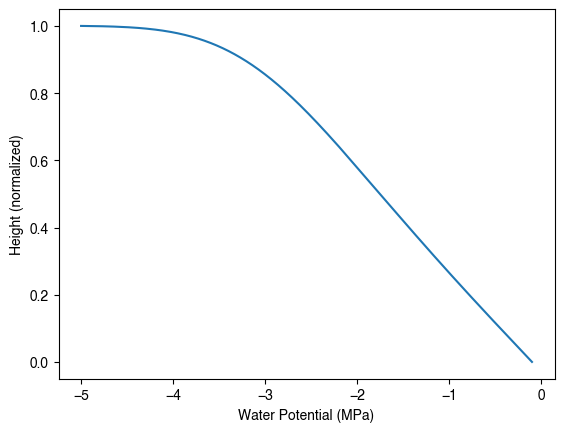

In [9]:
# Set the initial water potentials
psi_root = -0.1  # Water potential at the root zone
psi_leaf = -5.0  # Water potential at the leaf

xylem_water_potentials, storage_water_potentials = Get_initial_state(psi_root, psi_leaf, xylem_water_potentials, storage_water_potentials, k_max, sensetivity, shape, max_iterations=1000000, tolerance=1e-6)

plt.plot(xylem_water_potentials, np.linspace(0,1,len(xylem_water_potentials)), label='Xylem Water Potentials')
plt.xlabel('Water Potential (MPa)')
plt.ylabel('Height (normalized)')

# Run the simulation

For the first simulated run we start with the system in a stable state with a leaf water potential of $-5.0MPa$ before simulating stomatal closure by setting the leaf water potential equal to that of the root ($-0.1MPa$).

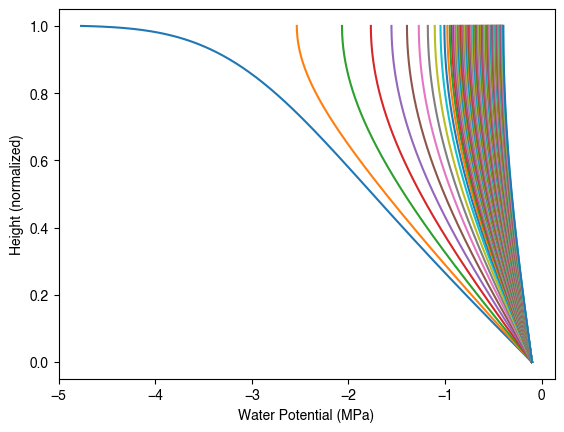

In [10]:
xylem_water_potentials[-1] = 0

delta_t = 1.0  # Time step in seconds

obs_leaf_water_potential = []
obs_0_25_water_potential = []
obs_0_50_water_potential = []
obs_0_75_water_potential = []

plt.plot(xylem_water_potentials[1:-1], np.linspace(0,1,len(xylem_water_potentials[1:-1])), label=f'Timestep 0')

obs_leaf_water_potential.append(cp.copy(xylem_water_potentials[-2]))  # Store the leaf water potential
obs_0_25_water_potential.append(cp.copy(xylem_water_potentials[int(len(xylem_water_potentials)/4)]))  # Store the water potential at 25% of the trunk height
obs_0_50_water_potential.append(cp.copy(xylem_water_potentials[int(len(xylem_water_potentials)/2)]))  # Store the water potential at the middle of the trunk
obs_0_75_water_potential.append(cp.copy(xylem_water_potentials[int(len(xylem_water_potentials)*3/4)]))  # Store the water potential at 75% of the trunk height

for i in range(100):
    for j in range(10000):
        # Update the xylem water potentials and storage water potentials
        xylem_water_potentials, storage_water_potentials = Step_time(xylem_water_potentials, storage_water_potentials, k_max, sensetivity, shape, xylem_to_storage_conductance, Capacitance, delta_t)
        
        obs_leaf_water_potential.append(cp.copy(xylem_water_potentials[-2]))
        obs_0_25_water_potential.append(cp.copy(xylem_water_potentials[int(len(xylem_water_potentials)/4)]))
        obs_0_50_water_potential.append(cp.copy(xylem_water_potentials[int(len(xylem_water_potentials)/2)]))
        obs_0_75_water_potential.append(cp.copy(xylem_water_potentials[int(len(xylem_water_potentials)*3/4)]))
    
    plt.plot(xylem_water_potentials[1:-1], np.linspace(0,1,len(xylem_water_potentials[1:-1])), label=f'Timestep {i+1}')

plt.xlabel('Water Potential (MPa)')
plt.ylabel('Height (normalized)')
plt.show()

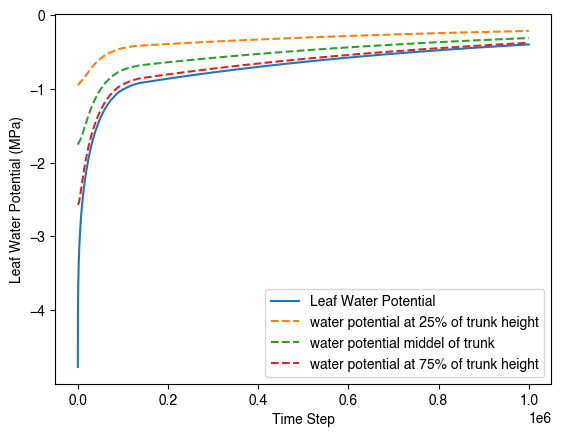

In [11]:
# Plot the leaf water potential over time
plt.plot(obs_leaf_water_potential, label='Leaf Water Potential')
plt.plot(obs_0_25_water_potential, label='water potential at 25% of trunk height', linestyle='--')
plt.plot(obs_0_50_water_potential, label='water potential middel of trunk', linestyle='--')
plt.plot(obs_0_75_water_potential, label='water potential at 75% of trunk height', linestyle='--')
plt.xlabel('Time Step')
plt.ylabel('Leaf Water Potential (MPa)')
plt.legend()
#plt.loglog()
plt.show()


/var/folders/qd/r8_04ccx1hlf_x0k_jfklmv40000gq/T/ipykernel_4094/282830191.py:3: RuntimeWarning: overflow encountered in exp
  return (psi_init - psi_target) * np.exp(shape_parameter * t) + psi_target
/var/folders/qd/r8_04ccx1hlf_x0k_jfklmv40000gq/T/ipykernel_4094/282830191.py:3: RuntimeWarning: overflow encountered in multiply
  return (psi_init - psi_target) * np.exp(shape_parameter * t) + psi_target


Fitted parameters:
Initial Leaf Water Potential: -2.75e+00 MPa
Shape Parameter: -1.5487e-05
Target soil Water Potential: -5.87e-01 MPa


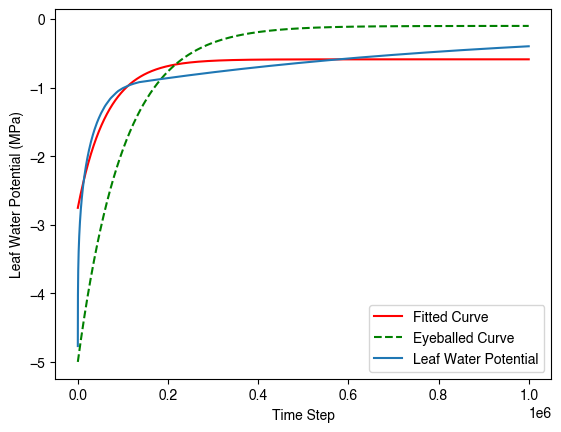

In [12]:
# Fit exponential decay to the leaf water potential
def exponential_decay(t, psi_init, shape_parameter, psi_target):
    return (psi_init - psi_target) * np.exp(shape_parameter * t) + psi_target

# Fit the model to the data
out = optimize.curve_fit(exponential_decay, np.arange(len(obs_leaf_water_potential)), obs_leaf_water_potential, p0=[-5.0, -0.01, -0.1])

psi_init_exp = out[0][0]
shape_parameter_exp = out[0][1]
psi_target_exp = out[0][2]

print("Fitted parameters:")
print(f"Initial Leaf Water Potential: {psi_init_exp:.2e} MPa")
print(f"Shape Parameter: {shape_parameter_exp:.4e}")
print(f"Target soil Water Potential: {psi_target_exp:.2e} MPa")

# Plot the fitted curve
t_fit = np.asarray([i * delta_t for i in range(len(obs_leaf_water_potential))])
plt.plot(t_fit, exponential_decay(t_fit, psi_init_exp, shape_parameter_exp, psi_target_exp), label='Fitted Curve', color='red')
plt.plot(t_fit, exponential_decay(t_fit, -5.0, -1e-5, -0.1), label='Eyeballed Curve', color='green', linestyle='--')
plt.plot(obs_leaf_water_potential, label='Leaf Water Potential')
plt.xlabel('Time Step')
plt.ylabel('Leaf Water Potential (MPa)')
plt.legend()
plt.show()

/var/folders/qd/r8_04ccx1hlf_x0k_jfklmv40000gq/T/ipykernel_4094/706018432.py:3: RuntimeWarning: overflow encountered in exp
  return (psi_init_exp - psi_target) * np.exp(shape_parameter_1 * np.exp(shape_parameter_2 * t)) + psi_target


Fitted parameters:
Initial Leaf Water Potential: -5.62e-01 MPa
Shape Parameter 1: 3.1680e+00
Shape Parameter 2: -5.8578e-06
Target soil Water Potential: -4.59e-01 MPa


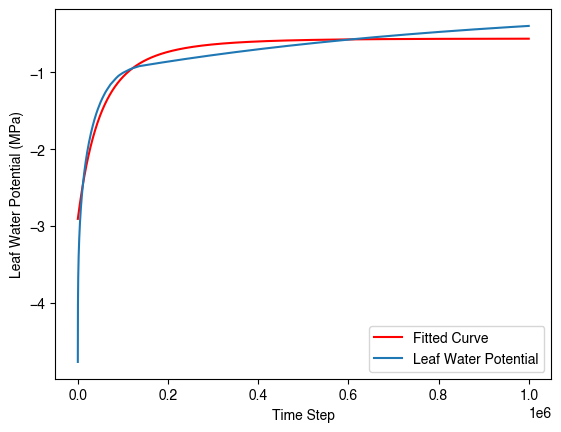

In [13]:
# Try the exponential of an exponential
def exponential_exponential_decay(t, psi_init_exp, shape_parameter_1, shape_parameter_2, psi_target):
    return (psi_init_exp - psi_target) * np.exp(shape_parameter_1 * np.exp(shape_parameter_2 * t)) + psi_target

# Fit the model to the data
out = optimize.curve_fit(exponential_exponential_decay, np.arange(len(obs_leaf_water_potential)), obs_leaf_water_potential, p0=[-5.0, -0.01, -0.01, -0.1])

psi_init_exp_exp = out[0][0]
shape_parameter_1_exp_exp = out[0][1]
shape_parameter_2_exp_exp = out[0][2]
psi_target_exp_exp = out[0][3]

print("Fitted parameters:")
print(f"Initial Leaf Water Potential: {psi_init_exp_exp:.2e} MPa")
print(f"Shape Parameter 1: {shape_parameter_1_exp_exp:.4e}")
print(f"Shape Parameter 2: {shape_parameter_2_exp_exp:.4e}")
print(f"Target soil Water Potential: {psi_target_exp_exp:.2e} MPa")

# Plot the fitted curve
t_fit = np.asarray([i * delta_t for i in range(len(obs_leaf_water_potential))])
plt.plot(t_fit, exponential_exponential_decay(t_fit, psi_init_exp_exp, shape_parameter_1_exp_exp, shape_parameter_2_exp_exp, psi_target_exp_exp), label='Fitted Curve', color='red')
#plt.plot(t_fit, exponential_exponential_decay(t_fit, -5.0, 3, -5e-6, -0.1), label='Eyeballed Curve', color='green', linestyle='--')
plt.plot(obs_leaf_water_potential, label='Leaf Water Potential')
plt.xlabel('Time Step')
plt.ylabel('Leaf Water Potential (MPa)')
plt.legend()
plt.show()

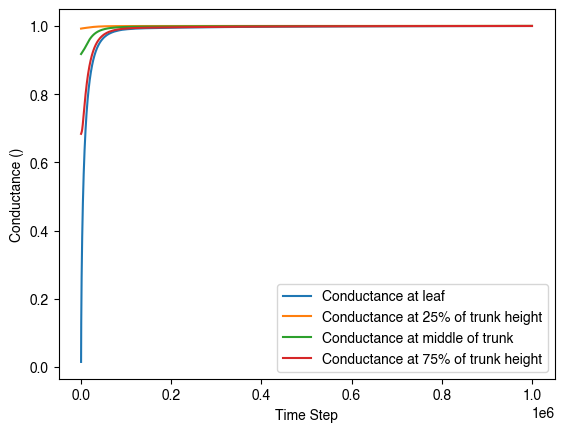

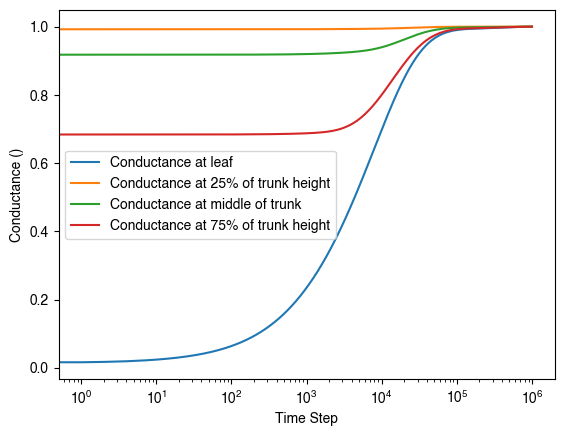

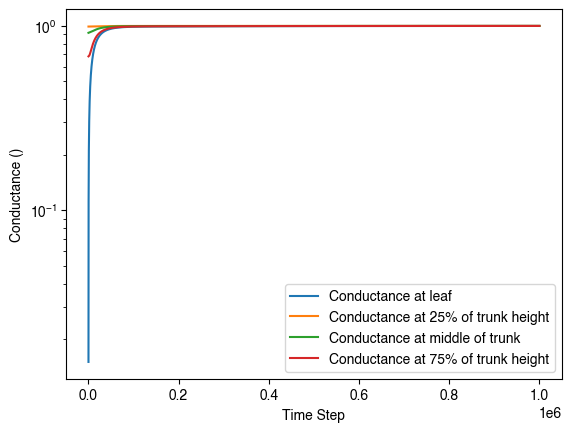

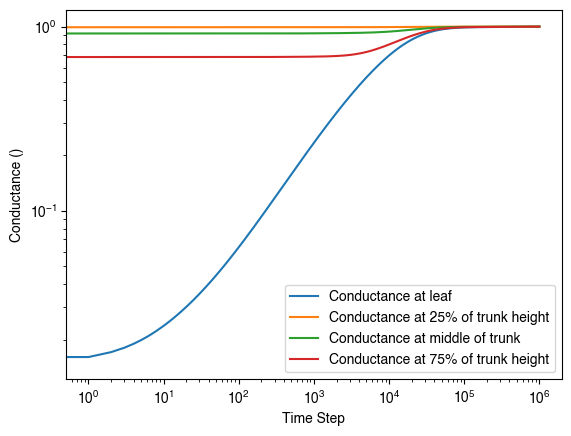

In [14]:
# Convert the leaf water potential to conductance and plot the conductance over time
obs_k = cumulative_Weibull_distribution(obs_leaf_water_potential, k_max, sensetivity, shape)
obs_k_0_25 = cumulative_Weibull_distribution(obs_0_25_water_potential, k_max, sensetivity, shape)
obs_k_0_50 = cumulative_Weibull_distribution(obs_0_50_water_potential, k_max, sensetivity, shape)
obs_k_0_75 = cumulative_Weibull_distribution(obs_0_75_water_potential, k_max, sensetivity, shape)

plt.plot(obs_k, label='Conductance at leaf')
plt.plot(obs_k_0_25, label='Conductance at 25% of trunk height')
plt.plot(obs_k_0_50, label='Conductance at middle of trunk')
plt.plot(obs_k_0_75, label='Conductance at 75% of trunk height')
plt.xlabel('Time Step')
plt.ylabel('Conductance ()')
plt.legend()
#plt.loglog()
plt.show()

plt.plot(obs_k, label='Conductance at leaf')
plt.plot(obs_k_0_25, label='Conductance at 25% of trunk height')
plt.plot(obs_k_0_50, label='Conductance at middle of trunk')
plt.plot(obs_k_0_75, label='Conductance at 75% of trunk height')
plt.xlabel('Time Step')
plt.ylabel('Conductance ()')
plt.xscale('log')
plt.legend()
plt.show()

plt.plot(obs_k, label='Conductance at leaf')
plt.plot(obs_k_0_25, label='Conductance at 25% of trunk height')
plt.plot(obs_k_0_50, label='Conductance at middle of trunk')
plt.plot(obs_k_0_75, label='Conductance at 75% of trunk height')
plt.xlabel('Time Step')
plt.ylabel('Conductance ()')
plt.yscale('log')
plt.legend()
plt.show()

plt.plot(obs_k, label='Conductance at leaf')
plt.plot(obs_k_0_25, label='Conductance at 25% of trunk height')
plt.plot(obs_k_0_50, label='Conductance at middle of trunk')
plt.plot(obs_k_0_75, label='Conductance at 75% of trunk height')
plt.xlabel('Time Step')
plt.ylabel('Conductance ()')
plt.loglog()
plt.legend()
plt.show()

/Users/jb14389/Desktop/Training/Getting started with tree models/profit-optimisation-model/profit_optimisation_model/src/HydraulicConductanceModels/cumulative_Weibull_distribution_model.py:104: RuntimeWarning: invalid value encountered in power
  exponent = - power(water_potentials / sensitivity_parameter, shape_parameter)


(array([-3.15498039,  7.48099636,  3.87641018]), array([[3.10062452e-07, 2.07735462e-07, 2.76307652e-07],
       [2.07735462e-07, 1.59442618e-07, 2.21404430e-07],
       [2.76307652e-07, 2.21404430e-07, 3.50772058e-07]]))
(array([3.44702898e+00, 1.18853170e+00, 2.05801218e-07]), array([[1.03488474e-04, 2.19244808e-05, 7.47539995e-05],
       [2.19244808e-05, 5.01052361e-06, 1.30056497e-05],
       [7.47539995e-05, 1.30056497e-05, 8.28851841e-05]]))


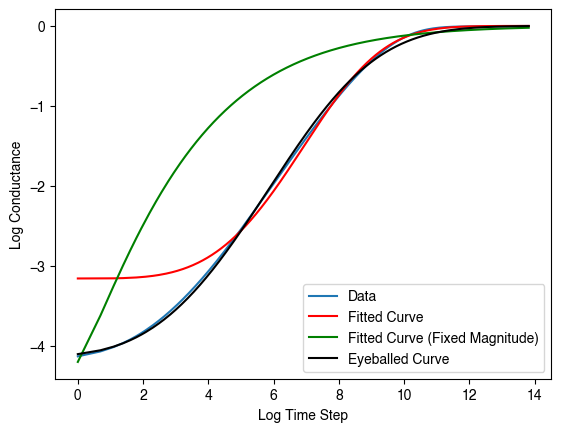

In [15]:
log_conductance = np.log(obs_k)
log_time = np.log(np.arange(1,len(obs_k)))

# Fit a cumulative Weibull distribution to the log-log data
output = optimize.curve_fit(cumulative_Weibull_distribution, log_time, log_conductance[1:], p0=[log_conductance[0], 4, 1])

print(output)

kmax = output[0][0]
sensetivity = output[0][1]
shape = output[0][2]

# Fit the cumulative Weibull distribution with fixed magnitude parameter
def cumulative_Weibull_distribution_fixed_magnitude(x, sensetivity, shape, offset):
    return cumulative_Weibull_distribution(x + offset, log_conductance[0], sensetivity, shape)
output = optimize.curve_fit(cumulative_Weibull_distribution_fixed_magnitude, log_time, log_conductance[1:], p0=[4, 1, 0])

print(output)

sensetivity_fixed_scale = output[0][0]
shape_fixed_scale = output[0][1]
offset_fixed_scale = output[0][2]

plt.plot(log_time, log_conductance[1:], label='Data')
plt.plot(log_time, cumulative_Weibull_distribution(log_time, kmax, sensetivity, shape), label='Fitted Curve', color='red')
plt.plot(log_time, cumulative_Weibull_distribution_fixed_magnitude(log_time, sensetivity_fixed_scale, shape_fixed_scale, offset_fixed_scale), label='Fitted Curve (Fixed Magnitude)', color='green')
plt.plot(log_time, cumulative_Weibull_distribution(log_time + 2, log_conductance[1], 8.7, 3.4), label='Eyeballed Curve', color='black')
plt.xlabel('Log Time Step')
plt.ylabel('Log Conductance')
plt.legend()
plt.show()